# A 64 s mock-data segment

Noise, one signal and one glitch, driven from Python the way `gwforge_noise`, `gwforge_inject` and `gwforge_glitch` do it. The guide pages are {doc}`../noise`, {doc}`../inject` and {doc}`../glitch`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import warnings
import numpy
import pylab
from gwpy.timeseries import TimeSeries  # gwpy restyles matplotlib on import, so it goes before the style line
from GWForge.plotting import new_rcParams, palette
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal  # noqa: E402, F401

pylab.rcParams.update(new_rcParams())
colours, colormap = palette()


/opt/anaconda3/envs/gwforge/lib/python3.11/site-packages/gwpy/time/_ligotimegps.py:42: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  from lal import LIGOTimeGPS


In [2]:
# ══════════════════════════════════════════════════════════════════════════════
# Coloured Gaussian noise for CE40 and ET. The same (seed, GPS time) always
# gives the same samples, which is what lets gwforge_noise be re-run per file.
# ET is a triangle, so bilby presents it as three interferometers.
# ══════════════════════════════════════════════════════════════════════════════
from GWForge.ifo.detectors import Network
from GWForge.ifo.reproducible_noise import noise_from_interferometer

FS, T0, DURATION = 4096, 1893024018, 64

network = Network(["CE40", "ET"]).initialise_ifos()
data = {}
for k, ifo in enumerate(network):
    samples, epoch = noise_from_interferometer(
        ifo, T0, T0 + DURATION, seed=k, sample_rate=FS, filter_duration=16
    )
    data[ifo.name] = TimeSeries(
        samples, t0=epoch, dt=1 / FS, name=f"{ifo.name}:INJ", channel=f"{ifo.name}:INJ"
    )

print({name: series.duration for name, series in data.items()})

{'CE40': <Quantity 64. s>, 'ET1': <Quantity 64. s>, 'ET2': <Quantity 64. s>, 'ET3': <Quantity 64. s>}


/opt/anaconda3/envs/gwforge/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/opt/anaconda3/envs/gwforge/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/opt/anaconda3/envs/gwforge/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


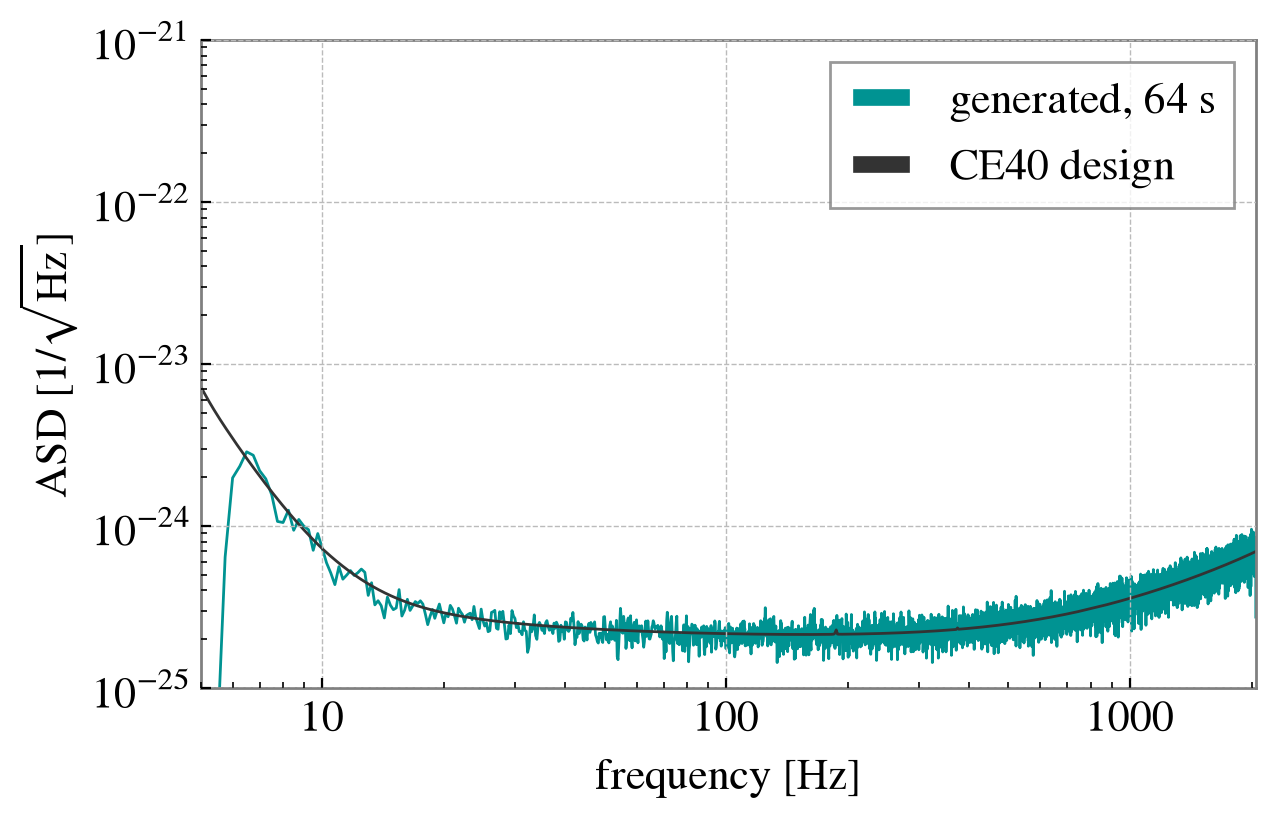

In [3]:
# ── Does the generated noise follow the design curve? ─────────────────────────
ifo = network[0]
asd = data["CE40"].asd(fftlength=4, method="median")

pylab.figure()
pylab.loglog(asd.frequencies.value, asd.value, color=colours[0], lw=1, label="generated, 64 s")
pylab.loglog(
    ifo.power_spectral_density.frequency_array,
    ifo.power_spectral_density.asd_array,
    color="0.2", lw=1, label="CE40 design",
)
pylab.xlim(5, FS / 2)
pylab.ylim(1e-25, 1e-21)
pylab.xlabel("frequency [Hz]")
pylab.ylabel(r"ASD [$1/\sqrt{\mathrm{Hz}}$]")
pylab.legend()

In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# One BBH, projected with the frequency-dependent, Earth-rotating response
# (the long-wavelength and static-pattern approximations are off by default)
# ══════════════════════════════════════════════════════════════════════════════
from GWForge.inject.bilby_inject import BilbyInject

injection = dict(
    mass_1=36.0, mass_2=29.0,
    a_1=0.3, a_2=0.2, tilt_1=0.5, tilt_2=1.0, phi_12=1.7, phi_jl=0.3,
    luminosity_distance=2000.0, theta_jn=0.4, psi=2.659, phase=1.3,
    geocent_time=T0 + 40.0, ra=1.375, dec=-1.2108,
)
waveform_arguments = dict(
    waveform_approximant="IMRPhenomXPHM", minimum_frequency=10.0, reference_frequency=10.0
)

injected = BilbyInject(["CE40", "ET"], data, injection, waveform_arguments).inject_signal_using_bilby_method()

for ifo in injected:
    print(f"{ifo.name:5s} optimal SNR {ifo.meta_data['optimal_SNR']:7.1f}")
print(f"network SNR {numpy.sqrt(sum(ifo.meta_data['optimal_SNR'] ** 2 for ifo in injected)):.1f}")

strain = {
    ifo.name: TimeSeries(ifo.time_domain_strain, times=ifo.time_array, channel=f"{ifo.name}:INJ")
    for ifo in injected
}

CE40  optimal SNR   460.3
ET1   optimal SNR   102.0
ET2   optimal SNR    85.2
ET3   optimal SNR   119.5
network SNR 493.8


In [5]:
# ══════════════════════════════════════════════════════════════════════════════
# One blip-like sine-Gaussian in CE40 only, scaled to optimal SNR 50 against
# the detector's PSD. gwforge_glitch draws these at a rate per hour, per detector.
# ══════════════════════════════════════════════════════════════════════════════
from GWForge.glitch.sine_gaussian import add_glitches

glitch = {k: numpy.asarray([v]) for k, v in dict(time=T0 + 20.0, frequency=100.0, q=10.0, snr=50.0, phase=0.0).items()}
amplitude = add_glitches(strain["CE40"].value, T0, FS, glitch, injected[0])

print(f"peak strain of the glitch: {amplitude[0]:.2e}")

peak strain of the glitch: 6.44e-23


Text(0, 0.5, 'whitened strain')

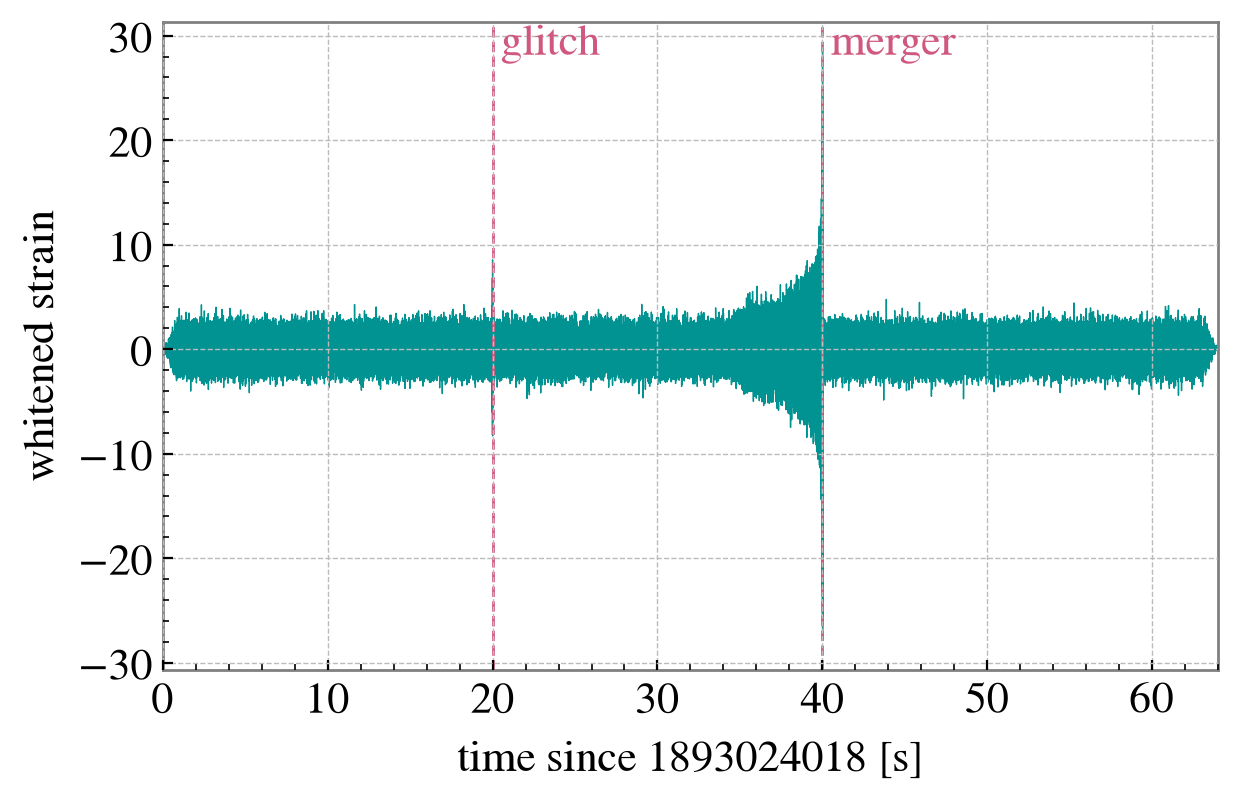

In [6]:
# ── The whitened CE40 strain, both events marked ──────────────────────────────
white = strain["CE40"].whiten(fftlength=4)

pylab.figure()
pylab.plot(white.times.value - T0, white.value, color=colours[0], lw=0.5)
for t, label in [(20, "glitch"), (40, "merger")]:
    pylab.axvline(t, color=colours[1], ls="--", lw=1)
    pylab.text(t + 0.5, 0.9 * pylab.ylim()[1], label, color=colours[1])
pylab.xlim(0, DURATION)
pylab.xlabel(f"time since {T0} [s]")
pylab.ylabel("whitened strain")

/opt/anaconda3/envs/gwforge/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "taiutc" yielded 1 of "dubious year (Note 4)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/opt/anaconda3/envs/gwforge/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "d2dtf" yielded 1 of "dubious year (Note 5)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)
/opt/anaconda3/envs/gwforge/lib/python3.11/site-packages/erfa/core.py:133: ErfaWarning: ERFA function "utctai" yielded 1 of "dubious year (Note 3)"
  warn(f'ERFA function "{func_name}" yielded {wmsg}', ErfaWarning)


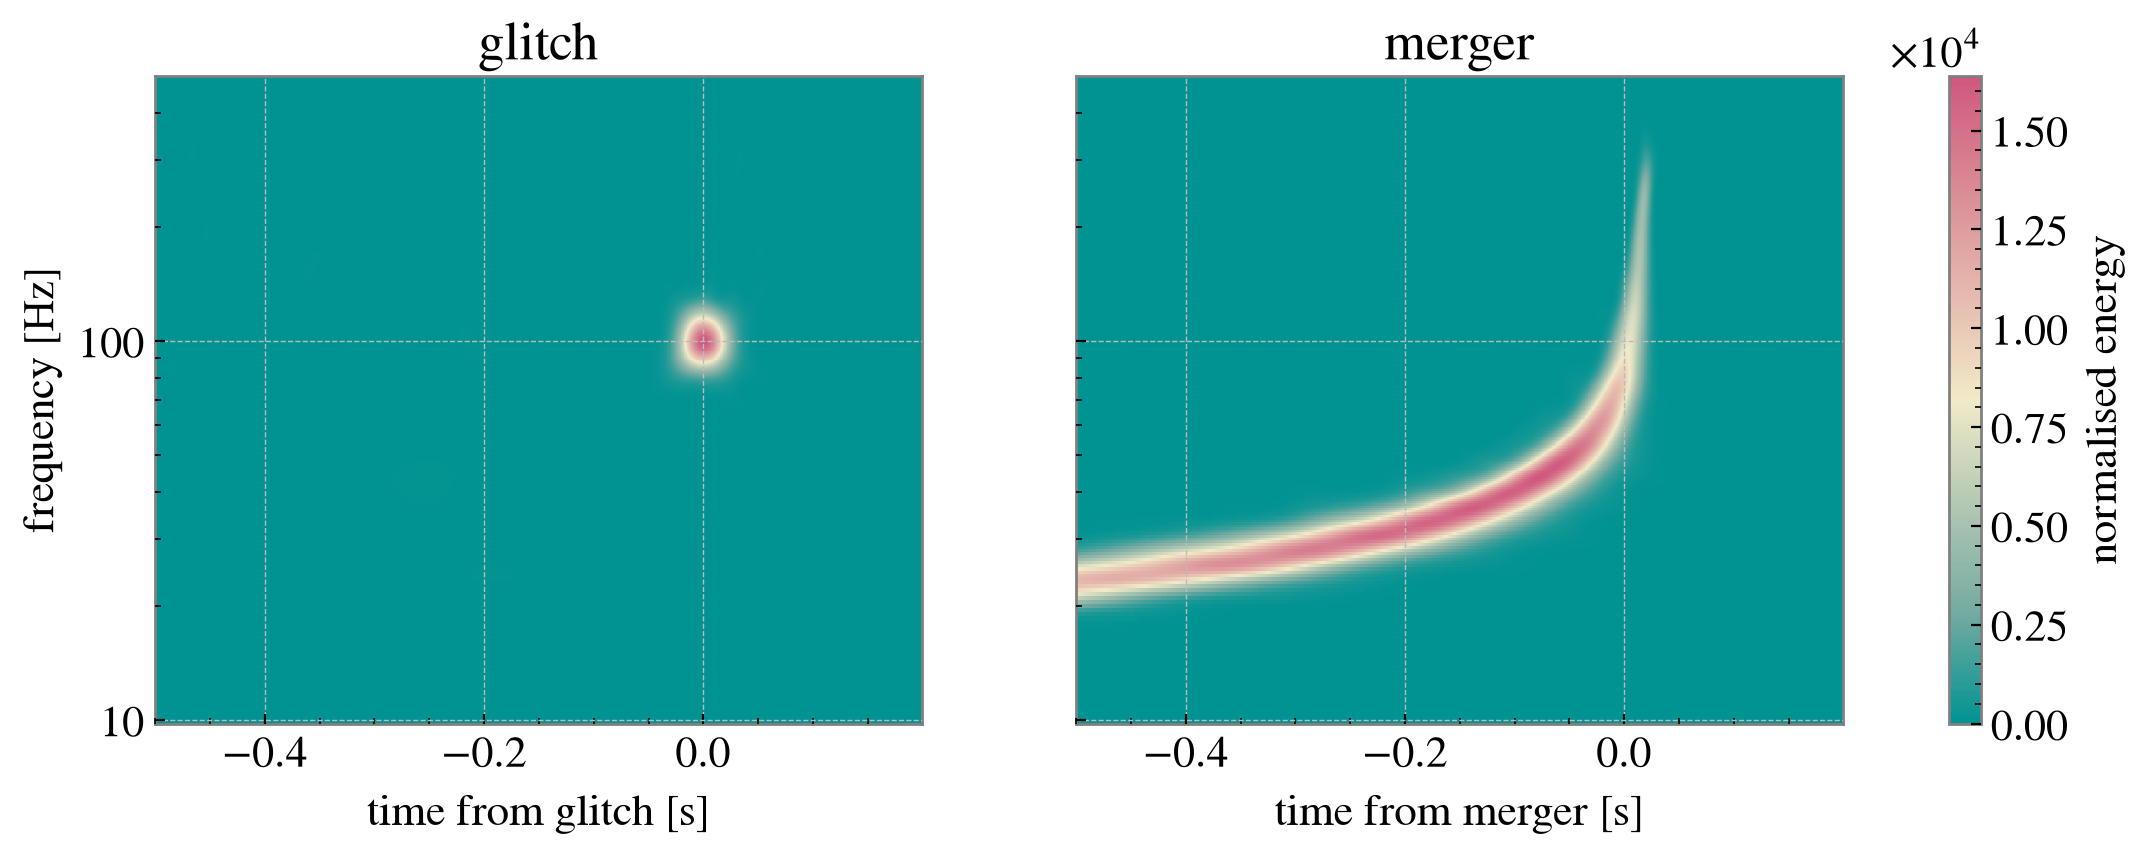

In [7]:
# ── Q-scans around each event (gwpy's q_transform; nothing in GWForge.plotting draws spectrograms)
width, height = pylab.rcParams["figure.figsize"]
fig, axes = pylab.subplots(1, 2, figsize=(2 * width, height), sharey=True)
for ax, (centre, label) in zip(axes, [(20.0, "glitch"), (40.0, "merger")]):
    q = strain["CE40"].q_transform(outseg=(T0 + centre - 0.5, T0 + centre + 0.2), frange=(10, 500))
    mesh = ax.pcolormesh(q.times.value - (T0 + centre), q.frequencies.value, q.value.T, cmap=colormap, shading="auto")
    ax.set_yscale("log")
    ax.set_title(label)
    ax.set_xlabel(f"time from {label} [s]")
axes[0].set_ylabel("frequency [Hz]")
fig.colorbar(mesh, ax=axes, label="normalised energy")

The scripts write each detector's series as an HDF5 frame with `GWForge.utils.save_frame_files`, under `<outdir>/<IFO>/<IFO>-<start>-<duration>.h5` with channel `<IFO>:INJ`, which is what the next stage reads back. The matching configuration sections are described on the three guide pages linked above.